In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import MultipleLocator, StrMethodFormatter
import matplotlib as mpl

from datetime import datetime

from reproject import reproject_interp
from reproject.mosaicking import find_optimal_celestial_wcs

from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS

%matplotlib widget

In [2]:
plt.rc('text', usetex=True)
plt.rc('font', family='serif')

# plt.rc('font', size=21)
# plt.rc('xtick', labelsize=21)
# plt.rc('ytick', labelsize=21)

fig_width_pt = 244.0  # Get this from LaTeX using \the\columnwidth
text_width_pt = 508.0 # Get this from LaTeX using \the\textwidth

inches_per_pt = 1.0/72.27               # Convert pt to inches
golden_mean = (np.sqrt(5)-1.0)/2.0         # Aesthetic ratio
fig_width = fig_width_pt*inches_per_pt*1.5 # width in inches
fig_width_full = text_width_pt*inches_per_pt*1.5  # 17
fig_height =fig_width*golden_mean # height in inches
fig_size = [fig_width,fig_height] #(9,5.5) #(9, 4.5)
fig_height_full = fig_width_full*golden_mean

fig_size_full = [fig_width_full,fig_height_full] #(9,5.5) #(9, 4.5)

In [3]:

miri_mrs_files = ['/Users/zalane/Python_Scripts/SN2024aecx/SN2024aecx_mrs_pfpc/SN2024aecx_2025-01-17_final/SN2024aecx_2025-01-17_abi_combined.ecsv', 
                  '/Users/zalane/Python_Scripts/SN2024aecx/SN2024aecx_mrs_pfpc/SN2024aecx_2025-06-01_final/SN2024aecx_2025-06-01_abi_combined.ecsv',
                  '/Users/zalane/Python_Scripts/SN2024aecx/SN2024aecx_mrs_pfpc/SN2024aecx_2025-12-07_final/SN2024aecx_2025-12-07_abi_combined.ecsv',
                  '/Users/zalane/Python_Scripts/SN2024aecx/SN2024aecx_mrs_pfpc/SN2024aecx_2025-12-28_final/SN2024aecx_2025-12-28_abi_combined.ecsv']

nirspec_files = [None,
                 '/Users/zalane/Python_Scripts/SN2024aecx/fs_data_09233_SN2024aecx/final_spectrum/2024aecx_s400a1_20250601_SN2024aecx_final.ecsv', 
                 None, 
                 '/Users/zalane/Python_Scripts/SN2024aecx/fs_data_09258_SN2024aecx/final_spectrum/2024aecx_s400a1_20251227_SN2024aecx_final.ecsv']

# nirspec_df = pd.read_csv(nirspec_file, comment='#', sep=r'\s+')

# nirspec_df


In [4]:
hdul = fits.open('/Users/zalane/Desktop/JWST-NIRCam-2024aecx/MAST/JWST/jw09258-o014_t002_nircam_clear-f070w_i2d.fits')
hdr = hdul[1].header
data = hdul[1].data
wcs = WCS(hdr)
hdul.close()

cmap_resampled = mpl.colormaps['rainbow'].resampled(6)
rgb_hex_strings = [mpl.colors.to_hex(cmap_resampled(i)) for i in range(6)]
filter_list = ['F070W', 'F090W', 'F115W', 'F150W', 'F356W', 'F444W']

master_wcs, shape_out = find_optimal_celestial_wcs((data, wcs), frame='icrs', auto_rotate=False)

ra, dec = 166.45643462, -0.0348496976029

sn_x, sn_y = master_wcs.all_world2pix(ra, dec, 0)  # replace ra and dec with the actual coordinates of the SN

image = np.load('/Users/zalane/Modules/AstroColour/SN2024aecx/colour_image_05-06-2025.npy')

print(sn_x, sn_y)


889.0189862129623 1544.3762900209356


Set DATE-AVG to '2026-06-05T09:39:10.464' from MJD-AVG.
Set DATE-END to '2026-06-05T09:44:00.387' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -34.811947 from OBSGEO-[XYZ].
Set OBSGEO-H to 1741512628.638 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
        Use numpy.iterable() instead. [reproject.mosaicking.wcs_helpers]


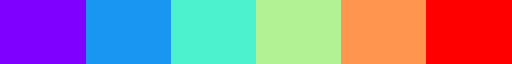

In [5]:
cmap_resampled

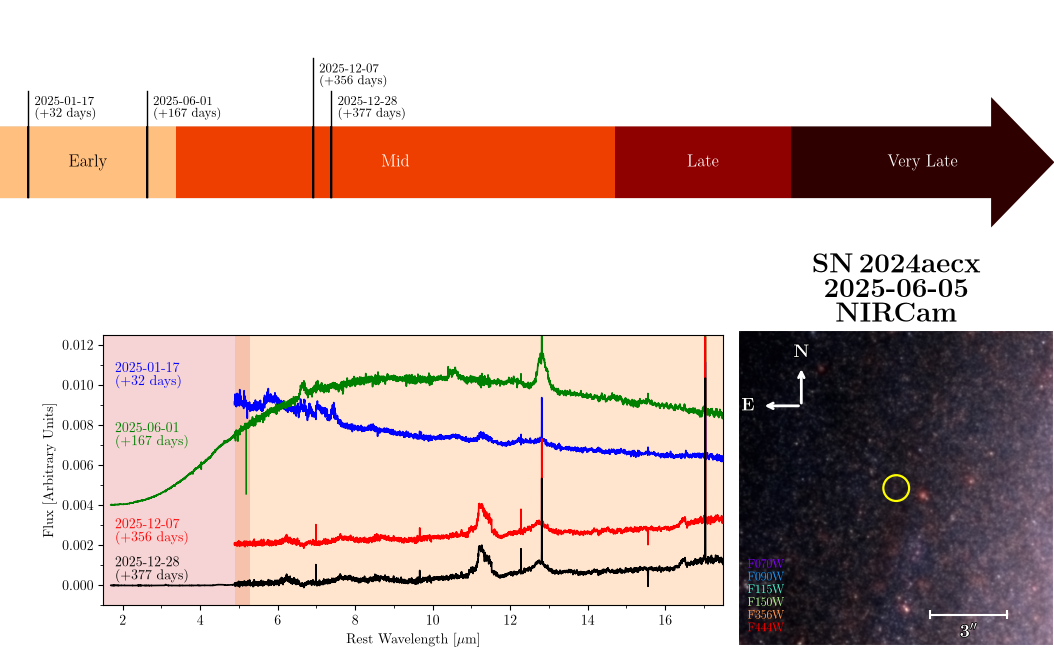

In [11]:
from three_panel_figure import make_figure, rainbow_filter_pieces

# fig, (ax_top, ax_spec, ax_img) = make_figure(
#     miri_mrs_files, nirspec_files, image, master_wcs, sn_x, sn_y,
#     filters=None,
# )
# ax_top.plot()        # fill the top panel
# # fig.savefig('three_panel.pdf')
# plt.show()


fig, (ax_top, ax_spec, ax_img) = make_figure(
    miri_mrs_files, nirspec_files, image, master_wcs, sn_x, sn_y,
    filters=rainbow_filter_pieces(['F070W','F090W','F115W','F150W','F356W','F444W']),
    z=0.002665,
    timeline_cmap='gist_heat_r',
    timeline_windows=[(0, 200, 'C0', 'Early'), (200, 700, 'C1', 'Mid'), (700, 900, 'C2', 'Late'), (900, 1200, 'C3', 'Very Late')],
    timeline_kw=dict(epochs=[32, 167, 356, 377]),   # optional
    obs_dates=['2025-01-17', '2025-06-01', ('2025-12-07', 'k'), '2025-12-28'],
    spec_ylim=(-0.001, 0.0125),
    # spectra_kw=dict(inset_height=0.25,
    #                 insets=[(3.9, 4.2, 'Title A'),
    #                         (4.2, 5.2, 'Title B', {'ylim': (0.0, 0.012)}),
    #                         (6.5, 8, 'Title C', {'ylim': (-0.001, 0.004)})]),
)

plt.savefig('three_panel.pdf', bbox_inches='tight')
plt.show()